Please upload an image:


Saving download.png to download.png
Enter initial window size (odd integer, e.g., 3): 5
Enter maximum window size Smax (odd integer > initial, e.g., 7): 9

--- Performance Comparison ---
Standard Median Filter (5x5) PSNR : 18.34 dB
Adaptive Median Filter (Smax=9) PSNR      : 21.46 dB


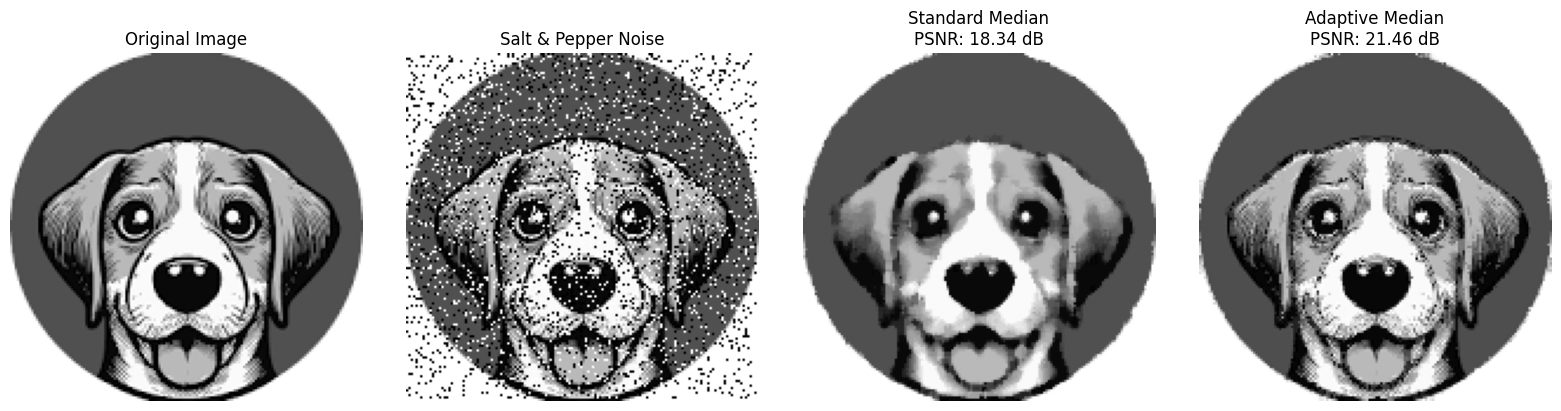

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

def add_salt_and_pepper_noise(image, salt_prob=0.05, pepper_prob=0.05):
    noisy = image.copy()
    num_salt = np.ceil(salt_prob * image.size)
    num_pepper = np.ceil(pepper_prob * image.size)

    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy[tuple(coords)] = 255

    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy[tuple(coords)] = 0
    return noisy

def calculate_psnr(original, processed):
    mse = np.mean((original.astype(np.float64) - processed.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    return 20 * np.log10(max_pixel / np.sqrt(mse))

def adaptive_median_filter(image, initial_window=3, s_max=7):
    rows, cols = image.shape
    output = np.copy(image)
    border = s_max // 2
    padded = cv2.copyMakeBorder(image, border, border, border, border, cv2.BORDER_REFLECT)

    for i in range(rows):
        for j in range(cols):
            w = initial_window
            center_val = image[i, j]

            while w <= s_max:
                half_w = w // 2
                r_start = (i + border) - half_w
                r_end = (i + border) + half_w + 1
                c_start = (j + border) - half_w
                c_end = (j + border) + half_w + 1

                window = padded[r_start:r_end, c_start:c_end]

                z_min = int(np.min(window))
                z_max = int(np.max(window))
                z_med = int(np.median(window))
                z_xy = int(center_val)

                a1 = z_med - z_min
                a2 = z_med - z_max

                if a1 > 0 and a2 < 0:
                    b1 = z_xy - z_min
                    b2 = z_xy - z_max
                    if b1 > 0 and b2 < 0:
                        output[i, j] = z_xy
                    else:
                        output[i, j] = z_med
                    break
                else:
                    w += 2
            else:
                output[i, j] = z_med

    return output

print("Please upload an image:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

original_img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

init_win = int(input("Enter initial window size (odd integer, e.g., 3): ") or 3)
s_max = int(input("Enter maximum window size Smax (odd integer > initial, e.g., 7): ") or 7)

noisy_img = add_salt_and_pepper_noise(original_img, salt_prob=0.1, pepper_prob=0.1)

standard_median_img = cv2.medianBlur(noisy_img, init_win)
adaptive_median_img = adaptive_median_filter(noisy_img, initial_window=init_win, s_max=s_max)

psnr_standard = calculate_psnr(original_img, standard_median_img)
psnr_adaptive = calculate_psnr(original_img, adaptive_median_img)

print(f"\n--- Performance Comparison ---")
print(f"Standard Median Filter ({init_win}x{init_win}) PSNR : {psnr_standard:.2f} dB")
print(f"Adaptive Median Filter (Smax={s_max}) PSNR      : {psnr_adaptive:.2f} dB")

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(original_img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(noisy_img, cmap='gray')
plt.title('Salt & Pepper Noise')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(standard_median_img, cmap='gray')
plt.title(f'Standard Median\nPSNR: {psnr_standard:.2f} dB')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(adaptive_median_img, cmap='gray')
plt.title(f'Adaptive Median\nPSNR: {psnr_adaptive:.2f} dB')
plt.axis('off')

plt.tight_layout()
plt.show()

Please upload an image for Otsu Thresholding:


Saving sunset.jpg to sunset.jpg
Otsu's Optimal Computed Threshold Value: 99.0


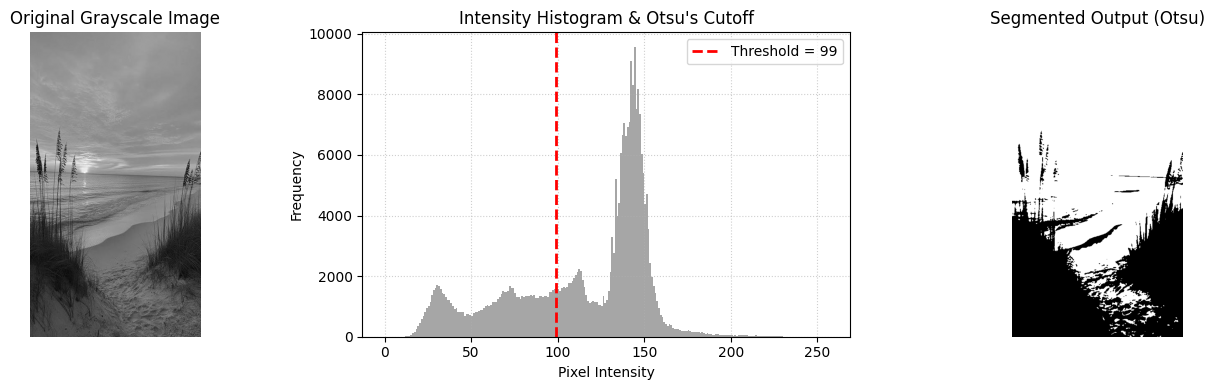

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Please upload an image for Otsu Thresholding:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

blurred = cv2.GaussianBlur(img, (5, 5), 0)


otsu_thresh_val, segmented_img = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

print(f"Otsu's Optimal Computed Threshold Value: {otsu_thresh_val}")

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.hist(blurred.ravel(), bins=256, range=[0, 256], color='gray', alpha=0.7)
plt.axvline(x=otsu_thresh_val, color='red', linestyle='--', linewidth=2, label=f'Threshold = {int(otsu_thresh_val)}')
plt.title("Intensity Histogram & Otsu's Cutoff")
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.subplot(1, 3, 3)
plt.imshow(segmented_img, cmap='gray')
plt.title(f"Segmented Output (Otsu)")
plt.axis('off')

plt.tight_layout()
plt.show()